In [1]:
import pandas as pd
import geopandas as gpd
from shapely.wkt import loads
from IPython.display import Image
import folium
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

/Users/stephenmarcou/opt/anaconda3/lib/python3.9/site-packages/geopandas/_compat.py:124: UserWarning: The Shapely GEOS version (3.11.1-CAPI-1.17.1) is incompatible with the GEOS version PyGEOS was compiled with (3.10.4-CAPI-1.16.2). Conversions between both will be slow.
  warnings.warn(
/var/folders/wb/9whmmh7s5bvf174ppr2jwprr0000gn/T/ipykernel_87510/3413139122.py:2: DeprecationWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas still uses PyGEOS by default. However, starting with version 0.14, the default will switch to Shapely. To force to use Shapely 2.0 now, you can either uninstall PyGEOS or set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In the next release, GeoPandas will switch to using Shapely by default, even if PyGEOS is installed. If you only have PyGEOS installed to get speed-ups, this switch 

# Identifying top features for rent price prediction (question 1)

This is the complete dataset used for predicting 2023 rent prices. It has merged property data with distance to school, uni, hospitals, train station, city centre, offence count, average family size, resident population, average household income in the area etc.



In [2]:
xgboost_data_2023 = pd.read_csv("../data/curated/data_XGBoost_before_onehotencode.csv")
xgboost_data_2023.head()

,property type,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,...,closest_city_centre,coastal,closest_cc_dist,dist_to_melb,predicted median equivalised total household income (weekly) ($) 2023,predicted median weekly household rental payment ($) 2023,predicted average family size (no. of persons) 2023,predicted employment ratio 2023,predicted estimated resident population (no.) 2023,predicted total dwellings (no.) 2023
0,House,1,2,6,120,0.586504,2.491226,True,7.430317,2.104719,...,Melbourne,False,11.566742,12.618789,1567.422222,487.077778,3.030000,0.952619,42748.566667,18091.000000
1,House,9,2,2,130,1.372612,2.438191,False,0.675843,6.688022,...,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
2,House,1,1,0,140,4.858273,3.301447,True,47.278807,10.766412,...,Cranbourne,False,37.174742,58.248165,985.433333,429.133333,2.700000,0.967222,13759.066667,9143.000000
3,House,1,2,6,140,1.114181,1.998214,False,1.502495,6.057051,...,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
4,House,1,4,3,150,0.215009,1.989564,False,1.862509,5.472987,...,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667


This is the list of the features used in the model

In [3]:
list(xgboost_data_2023.columns)

['property type',
 'beds',
 'baths',
 'parking',
 'weekly rent amount',
 'distance primary school',
 'distance secondary school',
 'is closest school good',
 'distance university campus',
 'distance to closest hospital',
 'offence count 2023',
 'distance train station',
 'city_centre',
 'closest_city_centre',
 'coastal',
 'closest_cc_dist',
 'dist_to_melb',
 'predicted median equivalised total household income (weekly) ($) 2023',
 'predicted median weekly household rental payment ($) 2023',
 'predicted average family size (no. of persons) 2023',
 'predicted employment ratio 2023',
 'predicted estimated resident population (no.) 2023',
 'predicted total dwellings (no.) 2023']

# XGBoost performance 

Split the dataset into 80-20 train and test split. Model was trained thorugh gridsearch on training set and tested on test set

Bar plot of the average error in prediction for each rent price. Error is defined as abs(true price - predicted price)

From the bar plot we can see that the errors increase at the extreme rent prices (less than 200 per week and over 1000 per week). This makes sense as the training and test set has less properties within these price ranges  

Text(0.5, 1.0, 'True Rent Price vs Averate Prediction Error Bar Plot')

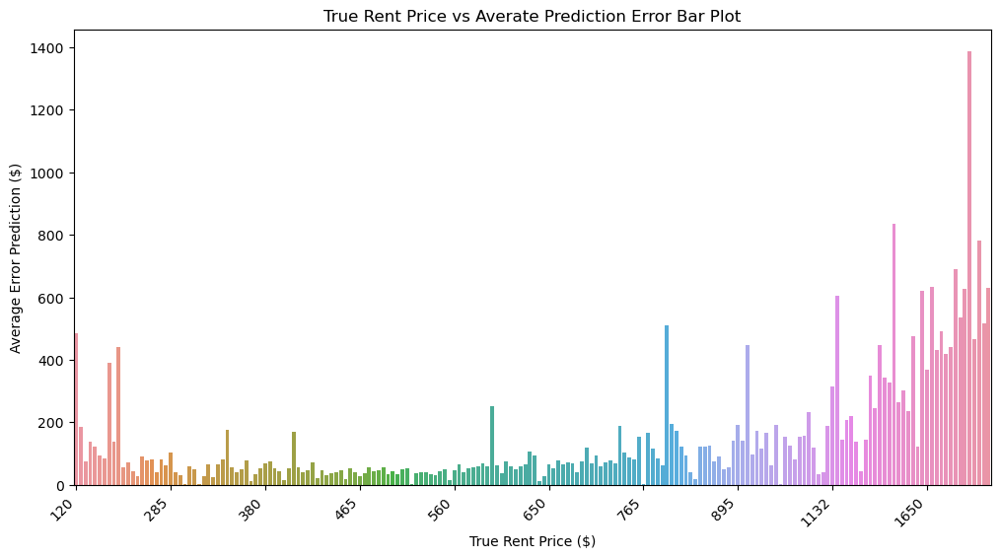

In [4]:
# read in file with average error per rent price
average_error_rent_price = pd.read_csv("../data/curated/average_error_rent_price.csv")

# Bar plot of average errors for rental price
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x="true rent price", y="error", data=average_error_rent_price, ax=ax)
tick_interval = 20  # Show every 20th label
x_values = list(average_error_rent_price["true rent price"])
visible_indices = range(0, len(x_values), tick_interval) 
visible_ticks = [x_values[i] for i in visible_indices]
ax.set_xticks(visible_indices)
ax.set_xticklabels(visible_ticks, rotation=45, ha='right')  # Rotate and align the labels
ax.set_xlabel("True Rent Price ($)")
ax.set_ylabel("Average Error Prediction ($)")
ax.set_title("True Rent Price vs Averate Prediction Error Bar Plot")

Boxplot of the predictions errors. From the boxplot, and especially from the 75 percentile value of error of 89.3, we can deduce that the model is performing adequately in predicting rent prices.

median error 46.18988037109375
25 percentile error 21.528411865234375
75 percentile error 89.30445861816406


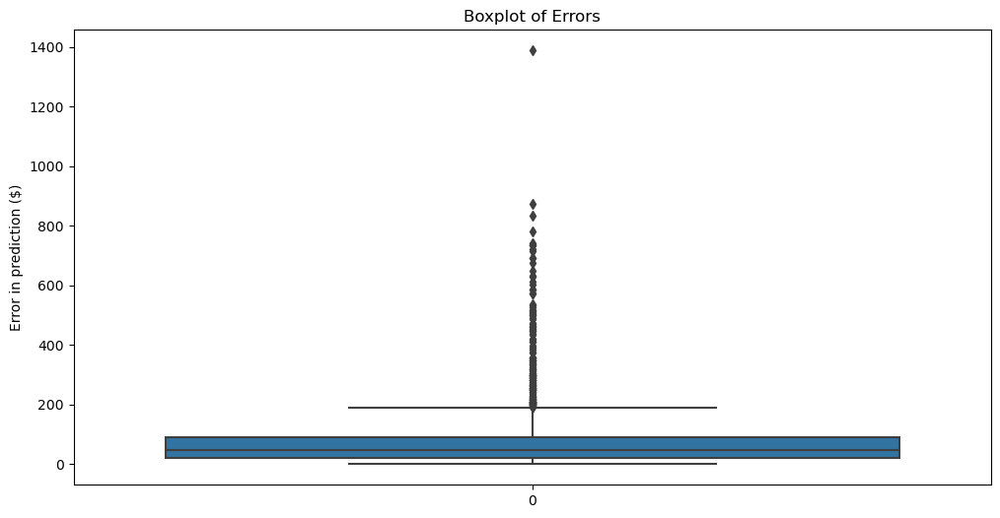

In [5]:
# read in file with error in prediction for all properites in test set
error_all_prop_test = pd.read_csv("../data/curated/error_predictions_test_set.csv")
# Boxplot of errors
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(error_all_prop_test["error"])
ax.set_ylabel("Error in prediction ($)")
ax.set_title("Boxplot of Errors")
print(f"median error {np.median(error_all_prop_test['error'])}")
print(f"25 percentile error {np.percentile(error_all_prop_test['error'], 25)}")
print(f"75 percentile error {np.percentile(error_all_prop_test['error'], 75)}")


# Question 1 Top features

As we can see distance to schools, number of bedrooms, distance to university, train station and hospitals are the most important features to predict rent price

In [6]:
top_features = pd.read_csv("../data/curated/top_features.csv")
top_features

,feature,weight
0,distance primary school,566.0
1,beds,525.0
2,distance secondary school,431.0
3,distance train station,402.0
4,distance university campus,371.0
5,distance to closest hospital,367.0
6,parking,280.0
7,baths,234.0
8,predicted median equivalised total household i...,207.0
9,predicted median weekly household rental payme...,197.0


# Growth Rate Analysis (Question 2)

For Question 2 we predicted the growth rate of postcodes in Victoria

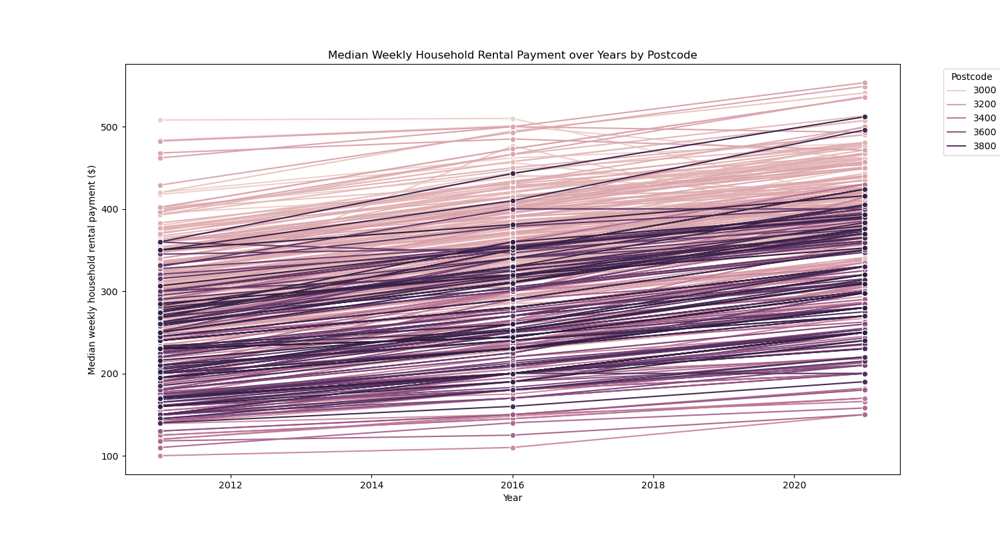

In [7]:
Image('../plots/preliminary_linear_analysis.png')

In [8]:
growth_rates = pd.read_csv("../data/curated/growth_rates.csv")

growth_rates.head()

,SA2_codes,Estimated resident population (no.),Population density (persons/km2),Employed (no.),Unemployed (no.),In the Labour force (no.),Total persons aged 15 years and over (no.),Median equivalised total household income (weekly) ($),Land area (ha),Median weekly household rental payment ($),Average family size (no. of persons),Total families (no.),Total dwellings (no.)
0,206041506,-0.026564,NaN,0.219170,0.142844,0.205934,0.155331,0.239006,NaN,0.061170,0.00,0.186442,0.069348
1,206041124,-0.044277,NaN,0.177702,0.053137,0.162510,0.088970,0.147364,NaN,0.035910,0.00,0.110920,0.042591
2,206041117,-0.082097,NaN,0.252636,0.222226,0.231786,0.123912,0.583360,NaN,0.039737,-0.02,0.115729,0.081057
3,206041503,-0.065621,NaN,0.273257,0.232402,0.263203,0.193417,0.207177,NaN,-0.045507,0.00,0.177838,0.046421
4,206041505,-0.013496,NaN,0.663590,0.757953,0.657995,0.554630,0.139851,NaN,-0.021125,0.00,0.525467,0.119887


Predicted Census data for SA2 districts

In [9]:
sa2_info_2026 = pd.read_csv('../data/curated/suburb_info_2026.csv')

sa2_info_2026.head()

,SA2_codes,Estimated resident population (no.),Population density (persons/km2),Employed (no.),Unemployed (no.),In the Labour force (no.),Total persons aged 15 years and over (no.),Median equivalised total household income (weekly) ($),Land area (ha),Median weekly household rental payment ($),Average family size (no. of persons),Total families (no.),Total dwellings (no.)
0,206041506,15573.0,NaN,10745.0,762.0,11430.0,16028.0,1587.166689,NaN,404.305913,2.600,3876.0,9920.0
1,206041124,7116.0,NaN,4687.0,464.0,5139.0,7416.0,1589.098519,NaN,410.220254,2.600,1146.0,2939.0
2,206041117,15786.0,NaN,10959.0,1395.0,12180.0,17725.0,1537.442265,NaN,379.503859,2.352,2893.0,11453.0
3,206041503,9535.0,NaN,7455.0,642.0,8050.0,11228.0,1408.775034,NaN,357.934956,2.300,2040.0,7717.0
4,206041505,15961.0,NaN,16850.0,1630.0,18329.0,23494.0,1272.073290,NaN,368.057013,2.200,4502.0,13446.0


These SA2 codes were turned to postcode granularity by checking each property's SA2 and aligning it with Postcode

In [10]:
postcode_info_2026 = pd.read_csv("../data/curated/postcode_info_2026.csv")

postcode_info_2026.head()

,Postcode,Estimated resident population (no.),Employed (no.),Unemployed (no.),In the Labour force (no.),Total persons aged 15 years and over (no.),Land area (ha),Total families (no.),Total dwellings (no.),Median equivalised total household income (weekly) ($),Median weekly household rental payment ($),Average family size (no. of persons)
0,3000,157031.0,119719.0,10414.0,129242.0,180530.0,0.0,41988.0,108362.0,1589.865710,423.457739,2.510361
1,3002,4718.0,3057.0,97.0,3151.0,4599.0,0.0,1260.0,3671.0,2172.310652,513.350649,2.302083
2,3003,24107.0,18438.0,1307.0,19641.0,25913.0,0.0,6567.0,16037.0,1513.938021,384.182262,2.501000
3,3004,109191.0,91135.0,7559.0,98106.0,132932.0,0.0,29229.0,83269.0,1595.423448,411.422507,2.407273
4,3006,40600.0,42974.0,2582.0,45964.0,61478.0,0.0,15497.0,32288.0,1823.873490,456.478563,2.504422


This census data for each postcode was then fed into the created XGBoost model for the predictions of rental prices in 2026

In [11]:
predictions = pd.read_csv('../data/curated/predictions_2026.csv')

predictions.head()

,beds,baths,parking,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,offence count 2023,distance train station,...,closest_city_centre_Melbourne,closest_city_centre_Morwell,closest_city_centre_Sale,closest_city_centre_Shepparton,closest_city_centre_Swan Hill,closest_city_centre_Traralgon,closest_city_centre_Wangaratta,closest_city_centre_Warrnambool,closest_city_centre_Wodonga,predicted weekly rent amount
0,1,2,6,0.586504,2.491226,True,7.430317,2.104719,29.0,1.667194,...,1,0,0,0,0,0,0,0,0,485.09930
1,1,1,0,0.951010,0.846483,False,9.427377,0.551691,29.0,0.672151,...,1,0,0,0,0,0,0,0,0,425.43277
2,2,1,0,0.449996,1.917181,True,10.270417,2.142153,29.0,1.148754,...,1,0,0,0,0,0,0,0,0,545.79840
3,2,1,1,0.824231,1.077620,False,9.001152,2.431453,29.0,0.236749,...,1,0,0,0,0,0,0,0,0,569.49725
4,3,1,1,0.232646,2.008062,False,8.589805,1.702026,29.0,0.467375,...,1,0,0,0,0,0,0,0,0,663.53690


We can then compare the growth rates between the predicted 2023 and 2026 data 

In [12]:
rent_data = pd.read_csv("../data/curated/weekly_rent_2023_and_2026.csv")

rent_data.head()

,postcode,weekly rent amount 2023,weekly rent amount 2026,growth_rate
0,3000,671.313536,673.14716,0.002731
1,3002,809.151515,704.01495,-0.129934
2,3003,600.779070,684.12680,0.138733
3,3004,709.277108,705.88696,-0.004780
4,3006,713.786667,646.61690,-0.094103


Map with the top 10 suburbs projected with the highest growth rate

In [13]:
sf = gpd.read_file("../data/landing/postcode/POA_2021_AUST_GDA2020.shp")
vic_suburbs = sf[sf["POA_CODE21"].astype(str).str.startswith('3')]
geoJSON = vic_suburbs[['POA_CODE21', 'geometry']].drop_duplicates('POA_CODE21').to_json()

vic_suburbs["POA_CODE21"] = vic_suburbs["POA_CODE21"].astype(int)
rent_data["postcode"] = rent_data["postcode"].astype(int)

gdf = gpd.GeoDataFrame(
    rent_data.merge(vic_suburbs, right_on='POA_CODE21', left_on='postcode', how='left')
)

gdf['geometry'] = gdf['geometry'].to_crs("+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs")
gdf['centroid'] = gdf['geometry'].apply(lambda x: (x.centroid.y, x.centroid.x))

df = gdf[["POA_CODE21", 'growth_rate']]

m = folium.Map(location=[-37.020100, 144.964600], tiles="Stamen Terrain", zoom_start=7)


# refer to the folium documentations on more information on how to plot aggregated data.
c = folium.Choropleth(
    geo_data=geoJSON, # geoJSON 
    name='choropleth', # name of plot
    data=df.reset_index(), # data source
    columns=["POA_CODE21", 'growth_rate'], # the columns required
    key_on= 'properties.POA_CODE21', # this is from the geoJSON's properties
    fill_color='viridis', # color scheme
    bins=10,
    nan_fill_color='white',
    legend_name='Growth rate of Weekly Rent'
)

c.add_to(m)

top_10_suburbs = df.sort_values(by = "growth_rate", ascending=False)["POA_CODE21"][:10].values

for suburb in top_10_suburbs:
    coord = gdf.loc[gdf["postcode"] == suburb]["centroid"].values
    m.add_child(
        folium.Marker(location=coord)
    )
    
m

/Users/stephenmarcou/opt/anaconda3/lib/python3.9/site-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


# Affordability Model

### Premliminary Findings

Initial exploration was aimed at looking for patterns in the data to determine any clear trends regarding affordability

In [14]:
df = pd.read_csv('../data/curated/median_weekly_rent_per_bed.csv')
df['geometry'] = df['geometry'].apply(lambda x: loads(x))
gdf = gpd.GeoDataFrame(df, geometry='geometry', crs='EPSG:4326')

# Create a Folium map centered around Melbourne
m = folium.Map(location=[-37.8136, 144.9631], tiles="Stamen Terrain", zoom_start=7)

# Create a Choropleth layer
folium.Choropleth(
    geo_data=gdf['geometry'], data=gdf['Median weekly rent per bed'], columns=['geometry', 'Average weekly rent per bed'],
    key_on='feature.id', fill_color='OrRd', fill_opacity=0.7, line_opacity=0.2, legend_name='Median Weekly Rent per Bed'
).add_to(m)

m

From the folium map there exists a clear pattern in price on a per bed basis and location. Melbourne and surrounding inner suburbs as well as East of Melbourne on average cost more. There other parts of Melbourne.

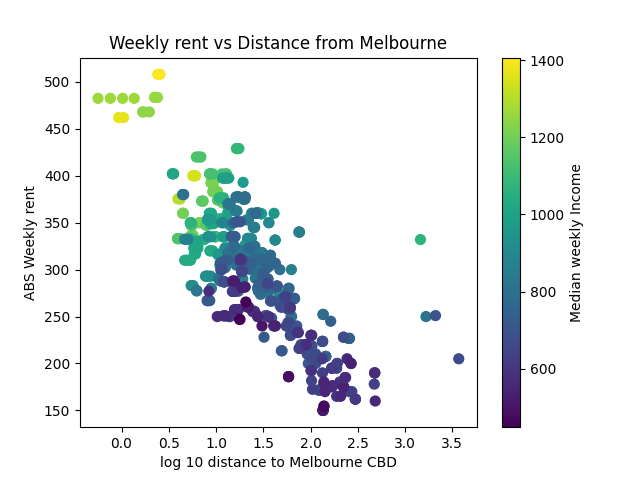

In [15]:
# Display the image
Image('../plots/Weekly_rent_vs_Distance_from_Melbourne.png')

From the scatterplot a clear linear trend is present between distance and weekly rent. Hence adjustments will have to be made to account for the fact locations closer to the CBD cost more. Moreover locations closer to the city have high median incomes meaning they have more capacity to meet rent obligations so they can afford to pay more for rent.

### Creation of affordability model

The affordability model cuts Victoria into multiple rings centered around the CBD. 

All properties within the ring have their Z score calculated for the affordability metrics created.
The affordability metrics include:
- Cost of rent normalised by number of bedrooms
- Proximity to train station
- Distance from Melbourne CBD
- Proportion of income going towards rent

A linear combination of the z scores was taken. With the lowest average score for a suburb being the most affordable suburb in a given ring for a given number of bedrooms.

In [16]:
affordability_results = pd.read_csv('../data/curated/most_affordable_suburbs.csv')
affordability_results

,Distance from Melbourne CBD,beds,index,Postcode,sum_z_scores,number of properties,cost_per_bed,rent as proportion of income,distance_to_melb_cbd_km,Suburb
0,"0, 2.5",1,0,3205,1.048227,21,500.000000,0.376105,1.672139,"['South Melbourne', 'Port Melbourne Industrial']"
1,"0, 2.5",2,1,3206,-1.089071,12,348.750000,0.336735,1.049680,"['Albert Park', 'South Melbourne', 'St Kilda -..."
2,"0, 2.5",3,2,3008,-0.784243,9,333.333333,0.361052,2.412458,"['Docklands', 'West Melbourne - Industrial', '..."
3,"0, 2.5",4,3,3207,0.024704,4,381.250000,0.380671,1.361180,"['Port Melbourne', 'Port Melbourne Industrial']"
4,"2.5, 5",1,4,3181,0.001367,33,400.000000,0.299750,4.487956,"['Prahran - Windsor', 'St Kilda - West']"
5,"2.5, 5",2,5,3182,-0.947199,52,300.000000,0.292105,4.055906,"['St Kilda East', 'St Kilda - West', 'St Kilda..."
6,"2.5, 5",3,6,3181,-0.835729,17,308.333333,0.299750,4.428889,"['Prahran - Windsor', 'St Kilda - West']"
7,"2.5, 5",4,7,3182,-0.947199,7,300.000000,0.292105,4.160871,"['St Kilda East', 'St Kilda - West', 'St Kilda..."
8,"5, 10",1,8,3078,0.080003,9,349.000000,0.304961,9.747619,"['Northcote - East', 'Clifton Hill - Alphingto..."
9,"5, 10",2,9,3015,-0.833775,12,230.000000,0.316977,6.431533,"['Altona North', 'Newport']"


The most affordable suburbs for a given ditance and number of bedrooms is displayed above, this is able to be filtered to suit the needs of individuals to determine where they potentially may want to live.